# Behavior video

This notebook reviews the behavior video stream of one converted session. The source is an overhead
video per session (`videos/MetaSession{N}.avi`, H.264 in an AVI container), acquired with SpinView. The
video is not copied into the NWB file: an `ImageSeries` stores the path to the AVI (`external_file`)
along with its frame rate and number of frames.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import ndx_pose  # noqa: F401
import pandas as pd
from hdmf.container import Container
from pynwb import NWBHDF5IO

In [2]:
nwb_file_path = Path("~/conversion_nwb/palop-lab-to-nwb/sub-63_ses-MetaSession3.nwb").expanduser()

io = NWBHDF5IO(nwb_file_path, "r")
nwbfile = io.read()

## NWB objects for this stream

In [3]:
summary = pd.DataFrame(
    [
        dict(
            name=neurodata_object.name,
            neurodata_type=neurodata_object.neurodata_type,
            namespace=neurodata_object.namespace,
            parent=neurodata_object.parent.name,
        )
        for neurodata_object in nwbfile.objects.values()
        if isinstance(neurodata_object, Container) and neurodata_object.parent is not None
    ]
)
summary[summary["name"].isin(["BehaviorVideo", "Camera3"])]

,name,neurodata_type,namespace,parent
1,Camera3,Device,core,root
64,BehaviorVideo,ImageSeries,core,root


The video should be a core `ImageSeries` in `acquisition` with `format="external"`, linked to a core
`Device` for the camera that recorded it.

In [4]:
behavior_video = nwbfile.acquisition["BehaviorVideo"]
print("external_file:", list(behavior_video.external_file[:]))
print("format:", behavior_video.format)
print("rate:", behavior_video.rate, "Hz")
print("starting_time:", behavior_video.starting_time, "s")
print("num_samples:", behavior_video.num_samples)
print("dimension:", list(behavior_video.dimension[:]))
print("device:", behavior_video.device.name, "-", behavior_video.device.description)

external_file: ['/Volumes/seagate_0/vame/J20/videos/MetaSession3.avi']
format: external
rate: 30.0 Hz
starting_time: 0.0 s
num_samples: 108271
dimension: [np.int64(1024), np.int64(1024)]
device: Camera3 - Overhead camera 3 of the four-arena open-field rig.


## Check against the source file

The external path is resolved relative to the NWB file, so the same code works after `dandi organize`
rewrites it to a relative path. The frame count, frame rate and frame size stored in NWB should match
the AVI header.

In [5]:
video_path = nwb_file_path.parent / behavior_video.external_file[0]
capture = cv2.VideoCapture(str(video_path))
video_header = dict(
    num_frames=int(capture.get(cv2.CAP_PROP_FRAME_COUNT)),
    fps=capture.get(cv2.CAP_PROP_FPS),
    width=int(capture.get(cv2.CAP_PROP_FRAME_WIDTH)),
    height=int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT)),
)
capture.release()

pd.DataFrame(
    dict(
        nwb=[behavior_video.num_samples, behavior_video.rate, *behavior_video.dimension[:]],
        avi_header=list(video_header.values()),
    ),
    index=list(video_header),
)

,nwb,avi_header
num_frames,108271,108271.0
fps,30.0,30.0
width,1024,1024.0
height,1024,1024.0


## Frames across the session

In [6]:
def read_frame(video_path: Path, frame_index: int):
    capture = cv2.VideoCapture(str(video_path))
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    success, frame = capture.read()
    capture.release()
    if not success:
        raise IOError(f"Could not read frame {frame_index} from {video_path}.")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

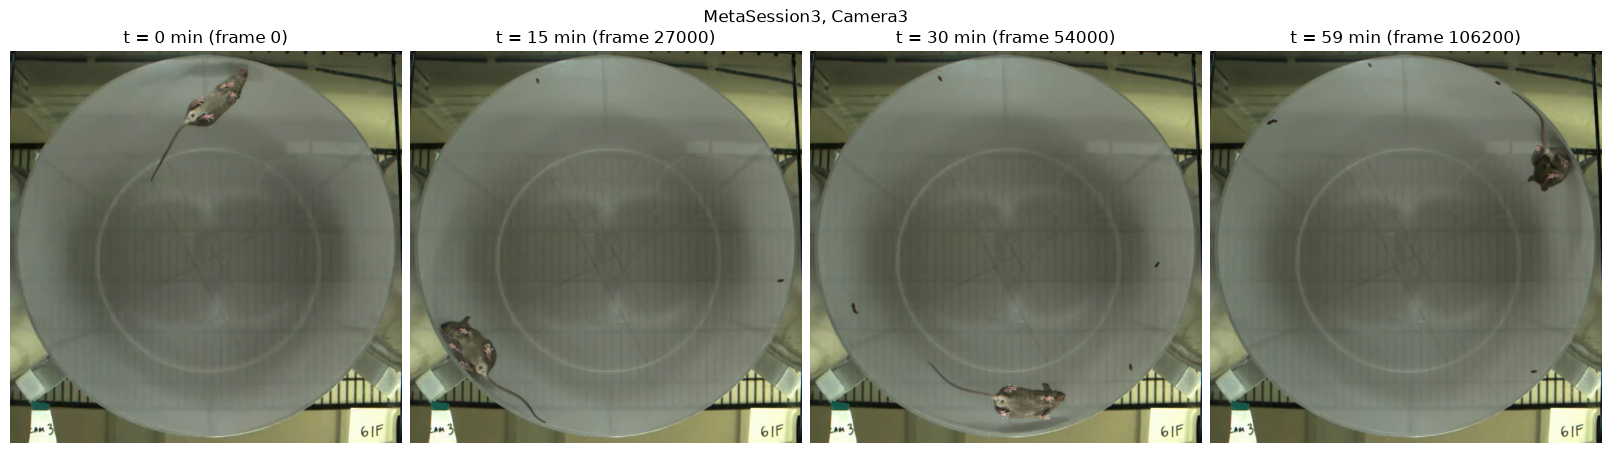

In [7]:
frame_times = [0, 15 * 60, 30 * 60, 59 * 60]

fig, axes = plt.subplots(1, len(frame_times), figsize=(16, 4.5), constrained_layout=True)
for ax, frame_time in zip(axes, frame_times):
    frame_index = int((frame_time - behavior_video.starting_time) * behavior_video.rate)
    ax.imshow(read_frame(video_path, frame_index))
    ax.set_title(f"t = {frame_time / 60:.0f} min (frame {frame_index})")
    ax.axis("off")
fig.suptitle(f"{nwbfile.session_id}, {behavior_video.device.name}")
plt.show()

In [8]:
io.close()